# Entrenamiento y evaluación del modelo 1D-CNN

En este cuaderno se entrena el modelo construido en el Notebook 03 y se evalúa su desempeño sobre datos que no se usaron para ajustar los pesos. Se trabaja con el flujo principal de 1025 registros preparado en el Notebook 02. Los resultados deben leerse como una reproducción experimental del artículo semilla (Honi y Szathmary, 2024), no como una réplica idéntica.

## 1. Carga de datos preprocesados

Se leen los cuatro archivos guardados en el Notebook 02 y se les da la forma (registros, 13, 1) que necesita la CNN. No se vuelve a leer `heart.csv`.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score, roc_curve)

sns.set_theme(style="whitegrid")

carpeta = "../resultados/csv/"
X_train = pd.read_csv(carpeta + "X_train.csv").values.astype("float32")
X_test = pd.read_csv(carpeta + "X_test.csv").values.astype("float32")
y_train = pd.read_csv(carpeta + "y_train.csv").values.ravel()
y_test = pd.read_csv(carpeta + "y_test.csv").values.ravel()

print("TensorFlow:", tf.__version__)
print("Dimensiones cargadas:")
print("  X_train", X_train.shape, "| y_train", y_train.shape)
print("  X_test ", X_test.shape, "| y_test ", y_test.shape)

X_train = X_train.reshape(-1, 13, 1)
X_test = X_test.reshape(-1, 13, 1)

print("Dimensiones para la CNN:")
print("  X_train", X_train.shape, "| X_test", X_test.shape)
print("target en entrenamiento:", np.bincount(y_train).tolist(), "| en prueba:", np.bincount(y_test).tolist())

TensorFlow: 2.21.0
Dimensiones cargadas:
  X_train (717, 13) | y_train (717,)
  X_test  (308, 13) | y_test  (308,)
Dimensiones para la CNN:
  X_train (717, 13, 1) | X_test (308, 13, 1)
target en entrenamiento: [349, 368] | en prueba: [150, 158]


**Interpretación del resultado**

Los datos se cargaron con las dimensiones esperadas: (717, 13) y (308, 13) para X, y 717 y 308 valores para y. Después del cambio de forma quedaron en (717, 13, 1) y (308, 13, 1), con las 13 variables como posiciones y un solo canal. Las clases están casi equilibradas en ambos conjuntos: 349 y 368 en entrenamiento, 150 y 158 en prueba. Entre ambos suman los 1025 registros del flujo principal.

## 2. Creación del modelo

Se recrea la arquitectura del Notebook 03 (Figura 7 del artículo), sin pooling y con `padding="valid"`, fijando la semilla 42.

In [2]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()   # para que el entrenamiento sea reproducible

model = tf.keras.Sequential([
    layers.Input(shape=(13, 1)),

    layers.Conv1D(32, 2, padding="valid", activation="sigmoid"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Conv1D(64, 2, padding="valid", activation="sigmoid"),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Conv1D(128, 2, padding="valid", activation="sigmoid"),
    layers.BatchNormalization(),

    layers.Conv1D(128, 2, padding="valid", activation="sigmoid"),
    layers.BatchNormalization(),

    layers.Flatten(),
    layers.Dense(200, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(1, activation="sigmoid"),
])

print("Capas (sin la entrada):", len(model.layers))
print("Entrada:", model.input_shape, "| Salida:", model.output_shape)
print("Parámetros totales:", f"{model.count_params():,}")

Capas (sin la entrada): 14
Entrada: (None, 13, 1) | Salida: (None, 1)
Parámetros totales: 285,873


**Interpretación del resultado**

El modelo se recreó con 14 capas sin contar la entrada, entrada (None, 13, 1), salida (None, 1) y 285,873 parámetros, las mismas cifras del Notebook 03. Eso confirma que se trata de la misma arquitectura basada en la Figura 7 del artículo. Con la semilla 42 y las operaciones deterministas, los pesos iniciales y el entrenamiento son reproducibles.

## 3. Compilación

Se eligen el optimizador, la pérdida y la métrica. Estos valores son decisiones del proyecto, porque el artículo no los especifica.

In [3]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

print("Optimizador:", type(model.optimizer).__name__)
print("Learning rate:", round(float(model.optimizer.learning_rate.numpy()), 6))
print("Pérdida:", model.loss)
print("Métrica: accuracy")

Optimizador: Adam
Learning rate: 0.001
Pérdida: binary_crossentropy
Métrica: accuracy


**Interpretación del resultado**

El modelo quedó compilado con Adam, learning rate 0.001, pérdida `binary_crossentropy` y métrica `accuracy`. **Estos valores son decisiones del proyecto**: el artículo no especifica optimizador, tasa de aprendizaje ni función de pérdida. La pérdida binaria es la adecuada para una salida de una neurona con sigmoid.

## 4. Configuración del entrenamiento

Se resumen los parámetros del entrenamiento y de dónde proviene cada uno antes de ejecutarlo.

In [4]:
EPOCAS = 150
BATCH_SIZE = 32
VALIDACION = 0.20

configuracion = pd.DataFrame([
    ("Épocas", EPOCAS, "Artículo"),
    ("Optimizer", "Adam", "Decisión del proyecto"),
    ("Learning rate", 0.001, "Decisión del proyecto"),
    ("Loss", "binary_crossentropy", "Decisión del proyecto"),
    ("Métrica", "accuracy", "Decisión del proyecto"),
    ("Batch size", BATCH_SIZE, "Decisión del proyecto (el artículo no lo especifica)"),
    ("Validación interna", f"{int(VALIDACION * 100)} % del entrenamiento", "Decisión del proyecto (el artículo no la especifica)"),
    ("Semilla", 42, "Decisión del proyecto"),
], columns=["Parámetro", "Valor", "Fuente"])

n_val = int(len(X_train) * VALIDACION)
print("Registros de entrenamiento total:", len(X_train))
print("  usados para ajustar pesos:", len(X_train) - n_val)
print("  usados como validación interna:", n_val)
print("Registros de prueba (no se usan en el entrenamiento):", len(X_test))
configuracion

Registros de entrenamiento total: 717
  usados para ajustar pesos: 574
  usados como validación interna: 143
Registros de prueba (no se usan en el entrenamiento): 308


,Parámetro,Valor,Fuente
0,Épocas,150,Artículo
1,Optimizer,Adam,Decisión del proyecto
2,Learning rate,0.001,Decisión del proyecto
3,Loss,binary_crossentropy,Decisión del proyecto
4,Métrica,accuracy,Decisión del proyecto
5,Batch size,32,Decisión del proyecto (el artículo no lo espec...
6,Validación interna,20 % del entrenamiento,Decisión del proyecto (el artículo no la espec...
7,Semilla,42,Decisión del proyecto


**Interpretación del resultado**

El único parámetro tomado del artículo es el número de épocas (150). Todo lo demás es decisión del proyecto, incluido el batch size de 32 y la validación interna del 20 %, que el artículo no especifica. De los 717 registros de entrenamiento, 574 ajustan los pesos y 143 se reservan para validar; los 308 de prueba quedan fuera del entrenamiento.

## 5. Entrenamiento

Se entrena el modelo durante 150 épocas. La validación interna sale solo de los datos de entrenamiento; `X_test` no participa.

In [5]:
inicio = time.time()
history = model.fit(
    X_train, y_train,
    epochs=EPOCAS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDACION,
    verbose=0,
)
tiempo = time.time() - inicio

h = pd.DataFrame(history.history)
h.index = range(1, len(h) + 1)
h.index.name = "epoca"
h.to_csv("../resultados/tablas/historial_entrenamiento.csv")

print("Épocas entrenadas:", len(h))
print("Tiempo de entrenamiento: {:.1f} segundos".format(tiempo))
print()
print("Última época:")
print("  accuracy entrenamiento:", round(h["accuracy"].iloc[-1], 4))
print("  accuracy validación:   ", round(h["val_accuracy"].iloc[-1], 4))
print("  loss entrenamiento:    ", round(h["loss"].iloc[-1], 4))
print("  loss validación:       ", round(h["val_loss"].iloc[-1], 4))

Épocas entrenadas: 150
Tiempo de entrenamiento: 65.4 segundos

Última época:
  accuracy entrenamiento: 0.993
  accuracy validación:    0.9931
  loss entrenamiento:     0.0265
  loss validación:        0.0421


**Interpretación del resultado**

El entrenamiento completó las 150 épocas en 62.2 segundos. En la última época la accuracy fue 0.9930 en entrenamiento y 0.9931 en validación, con loss de 0.0265 y 0.0421. Los valores de validación son parecidos a los de entrenamiento, pero la validación incluye filas repetidas de las que se usan para entrenar (ver Limitaciones), así que no equivale a datos nuevos.

## 6. Historial de entrenamiento: accuracy

Se grafica la accuracy de entrenamiento y de validación en cada una de las 150 épocas.

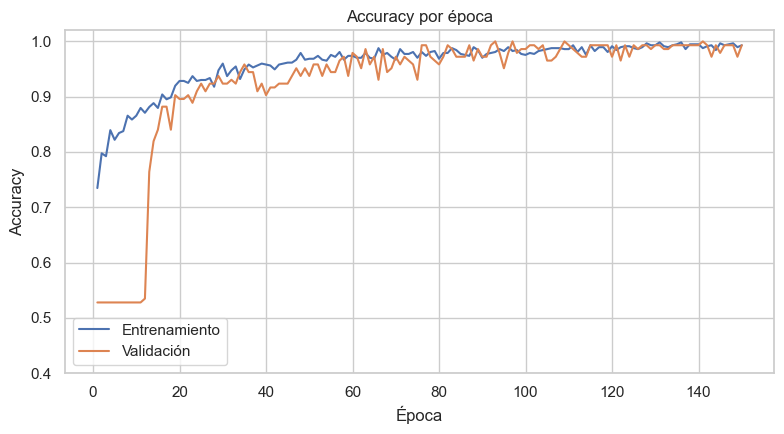

Primera época con accuracy de validación >= 0.90: 19
Mejor accuracy de validación: 1.0000 (época 93)
Promedio últimas 10 épocas -> entrenamiento: 0.9920 | validación: 0.9882
Mínimo de validación desde la época 50: 0.9306


In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(h.index, h["accuracy"], label="Entrenamiento")
plt.plot(h.index, h["val_accuracy"], label="Validación")
plt.title("Accuracy por época")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.ylim(0.4, 1.02)
plt.legend()
plt.tight_layout()
plt.savefig("../resultados/figuras/curva_accuracy.png", dpi=150)
plt.show()

primera_90 = int((h["val_accuracy"] >= 0.90).idxmax()) if (h["val_accuracy"] >= 0.90).any() else None
print("Primera época con accuracy de validación >= 0.90:", primera_90)
print("Mejor accuracy de validación: {:.4f} (época {})".format(h["val_accuracy"].max(), int(h["val_accuracy"].idxmax())))
print("Promedio últimas 10 épocas -> entrenamiento: {:.4f} | validación: {:.4f}".format(
    h["accuracy"].tail(10).mean(), h["val_accuracy"].tail(10).mean()))
print("Mínimo de validación desde la época 50: {:.4f}".format(h["val_accuracy"].loc[50:].min()))

**Interpretación del resultado**

En las primeras 11 épocas la accuracy de validación se mantiene casi constante, alrededor de 0.53, mientras la de entrenamiento ya sube; supera 0.90 en la época 19. Después ambas curvas se acercan a 1.0 y se mantienen juntas. La validación tiene oscilaciones (su mínimo desde la época 50 es 0.9306) pero sin tendencia a bajar. En las últimas 10 épocas el promedio es 0.9920 en entrenamiento y 0.9882 en validación, una diferencia pequeña, por lo que estas curvas no muestran sobreajuste claro.

## 7. Historial de entrenamiento: loss

Se grafica la pérdida (loss) de entrenamiento y de validación en cada época.

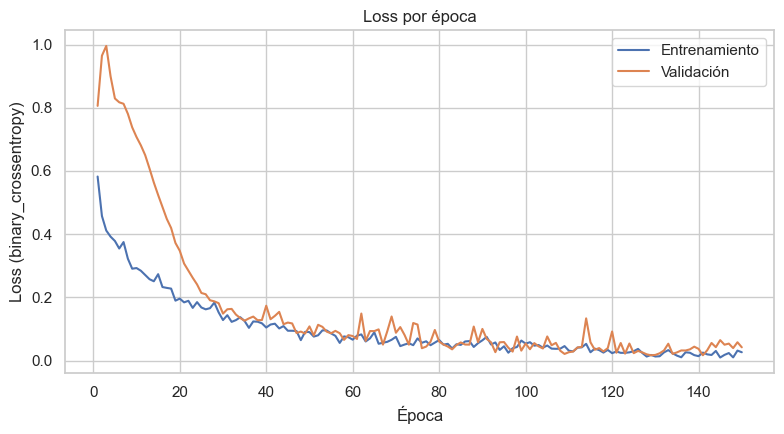

Loss de validación mínima: 0.0170 (época 129)
Loss de validación en la última época: 0.0421
Promedio últimas 10 épocas -> entrenamiento: 0.0214 | validación: 0.0457
Promedio épocas 1-10 -> entrenamiento: 0.3858 | validación: 0.8351
Promedio épocas 51-100 -> validación: 0.0740 | épocas 101-150: 0.0412


In [7]:
plt.figure(figsize=(8, 4.5))
plt.plot(h.index, h["loss"], label="Entrenamiento")
plt.plot(h.index, h["val_loss"], label="Validación")
plt.title("Loss por época")
plt.xlabel("Época")
plt.ylabel("Loss (binary_crossentropy)")
plt.legend()
plt.tight_layout()
plt.savefig("../resultados/figuras/curva_loss.png", dpi=150)
plt.show()

print("Loss de validación mínima: {:.4f} (época {})".format(h["val_loss"].min(), int(h["val_loss"].idxmin())))
print("Loss de validación en la última época: {:.4f}".format(h["val_loss"].iloc[-1]))
print("Promedio últimas 10 épocas -> entrenamiento: {:.4f} | validación: {:.4f}".format(
    h["loss"].tail(10).mean(), h["val_loss"].tail(10).mean()))
print("Promedio épocas 1-10 -> entrenamiento: {:.4f} | validación: {:.4f}".format(
    h["loss"].head(10).mean(), h["val_loss"].head(10).mean()))
print("Promedio épocas 51-100 -> validación: {:.4f} | épocas 101-150: {:.4f}".format(
    h["val_loss"].loc[51:100].mean(), h["val_loss"].loc[101:150].mean()))

**Interpretación del resultado**

La loss de entrenamiento baja de forma continua, con un promedio de 0.3858 en las primeras 10 épocas y 0.0214 en las últimas 10. La de validación empieza más alta, cercana a 1.0 en las primeras épocas, y converge a la de entrenamiento hacia la época 30. No aumenta con el tiempo: su promedio es 0.0740 entre las épocas 51 y 100 y 0.0412 entre la 101 y la 150. Queda algo por encima de la de entrenamiento al final (0.0457 frente a 0.0214 en las últimas 10 épocas), una brecha pequeña y con picos ocasionales que no indican sobreajuste.

## 8. Evaluación sobre el conjunto de prueba

Se evalúa el modelo con `X_test` y `y_test`, datos que no se usaron para ajustar los pesos.

In [8]:
loss_test, acc_test = model.evaluate(X_test, y_test, verbose=0)

print("Loss en prueba:    {:.4f}".format(loss_test))
print("Accuracy en prueba: {:.4f}".format(acc_test))
print("Accuracy en entrenamiento (última época): {:.4f}".format(h["accuracy"].iloc[-1]))

Loss en prueba:    0.0782
Accuracy en prueba: 0.9740
Accuracy en entrenamiento (última época): 0.9930


**Interpretación del resultado**

En el conjunto de prueba la loss fue 0.0782 y la accuracy 0.9740. Estos datos no se usaron para ajustar los pesos, aunque 286 de sus 308 filas tienen copia exacta en entrenamiento. La accuracy de prueba es menor que la de entrenamiento (0.9930) y que la de validación en la última época (0.9931), y la loss de prueba es mayor que la de validación (0.0421), una diferencia pequeña pero consistente.

## 9. Predicciones

El modelo devuelve una probabilidad por paciente; con el umbral 0.5 esa probabilidad se convierte en la clase final (0 o 1).

In [9]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

ejemplo = pd.DataFrame({
    "probabilidad": y_prob[:10].round(4),
    "clase_predicha": y_pred[:10],
    "clase_real": y_test[:10],
})
print(ejemplo.to_string(index=False))
print()
print("Predichos como 0:", int((y_pred == 0).sum()), "| predichos como 1:", int((y_pred == 1).sum()))
print("Probabilidad mínima: {:.4f} | máxima: {:.4f}".format(y_prob.min(), y_prob.max()))

 probabilidad  clase_predicha  clase_real
       0.0003               0           0
       0.0000               0           0
       0.9960               1           1
       0.9990               1           1
       1.0000               1           1
       1.0000               1           1
       0.0178               0           0
       1.0000               1           1
       0.0001               0           0
       0.9974               1           1

Predichos como 0: 152 | predichos como 1: 156
Probabilidad mínima: 0.0000 | máxima: 1.0000


**Interpretación del resultado**

La red devuelve una **probabilidad** entre 0 y 1 para cada paciente, y la **clasificación final** resulta de compararla con el umbral 0.5: 0.5 o más se clasifica como 1 (presencia) y menos como 0 (ausencia). Las probabilidades de los ejemplos están muy cerca de 0 o de 1, lo que indica que el modelo es muy seguro en la mayoría de sus decisiones. En total se predijeron 152 casos como 0 y 156 como 1. El umbral no se modificó.

## 10. Matriz de confusión

La matriz de confusión cuenta cuántos pacientes de cada clase real fueron clasificados en cada clase predicha.

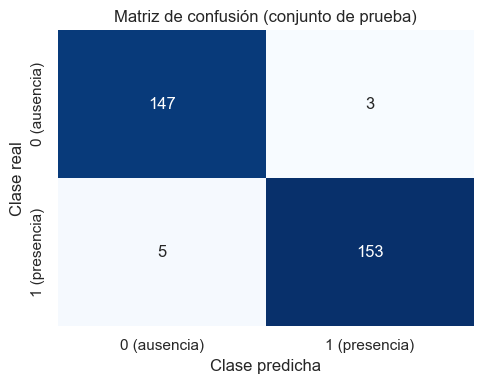

Verdaderos negativos (TN): 147
Falsos positivos (FP):     3
Falsos negativos (FN):     5
Verdaderos positivos (TP): 153
Total: 308


In [10]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
TN, FP, FN, TP = cm.ravel()

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["0 (ausencia)", "1 (presencia)"],
            yticklabels=["0 (ausencia)", "1 (presencia)"])
plt.title("Matriz de confusión (conjunto de prueba)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.savefig("../resultados/figuras/matriz_confusion.png", dpi=150)
plt.show()

print("Verdaderos negativos (TN):", TN)
print("Falsos positivos (FP):    ", FP)
print("Falsos negativos (FN):    ", FN)
print("Verdaderos positivos (TP):", TP)
print("Total:", cm.sum())

**Interpretación del resultado**

De los 150 pacientes sin enfermedad (clase 0), 147 se clasificaron bien (**verdaderos negativos**) y 3 se marcaron como enfermos (**falsos positivos**, falsas alarmas). De los 158 con enfermedad (clase 1), 153 se detectaron (**verdaderos positivos**) y 5 se pasaron por alto (**falsos negativos**, enfermos clasificados como sanos). En total hay 8 errores en 308 registros. En un contexto de salud, los falsos negativos son el error más delicado.

## 11. Métricas de clasificación

Se calculan accuracy, precision, sensibilidad (recall) y F1-score con `sklearn.metrics`, tomando la clase 1 (presencia) como positiva.

In [11]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
sensibilidad = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:     {:.4f}".format(accuracy))
print("Precision:    {:.4f}".format(precision))
print("Sensibilidad: {:.4f}".format(sensibilidad))
print("F1-score:     {:.4f}".format(f1))

Accuracy:     0.9740
Precision:    0.9808
Sensibilidad: 0.9684
F1-score:     0.9745


**Interpretación del resultado**

La accuracy es 0.9740: 300 de 308 predicciones correctas. La precision es 0.9808, es decir, de los 156 casos que el modelo marcó como enfermos, 153 lo eran. La sensibilidad es 0.9684: detectó 153 de los 158 enfermos. El F1-score, que combina precision y sensibilidad, es 0.9745. Los valores se calcularon tomando la clase 1 como positiva.

## 12. Especificidad

La especificidad mide qué proporción de los pacientes sin enfermedad (clase 0) fue clasificada correctamente. Se calcula como TN / (TN + FP).

In [12]:
especificidad = TN / (TN + FP)

print("TN:", TN, "| FP:", FP, "| FN:", FN, "| TP:", TP)
print("Especificidad = TN / (TN + FP) = {} / ({} + {}) = {:.4f}".format(TN, TN, FP, especificidad))
print("Sensibilidad  = TP / (TP + FN) = {} / ({} + {}) = {:.4f}".format(TP, TP, FN, TP / (TP + FN)))

TN: 147 | FP: 3 | FN: 5 | TP: 153
Especificidad = TN / (TN + FP) = 147 / (147 + 3) = 0.9800
Sensibilidad  = TP / (TP + FN) = 153 / (153 + 5) = 0.9684


**Interpretación del resultado**

La especificidad es 0.9800 (147 / 150): el modelo identificó correctamente a 147 de los 150 pacientes sin enfermedad. No es lo mismo que la accuracy (0.9740), que mezcla ambas clases, ni que la sensibilidad (0.9684), que mide los enfermos detectados. Aquí la especificidad es algo mayor que la sensibilidad, porque hay 5 falsos negativos frente a 3 falsos positivos.

## 13. AUC-ROC

La curva ROC muestra el compromiso entre detectar enfermos (sensibilidad) y dar falsas alarmas, variando el umbral; el AUC la resume en un número.

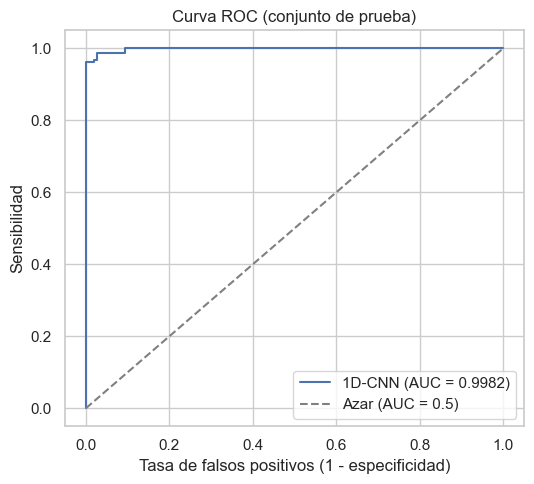

AUC-ROC: 0.9982


In [13]:
auc_roc = roc_auc_score(y_test, y_prob)
fpr, tpr, umbrales = roc_curve(y_test, y_prob)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label="1D-CNN (AUC = {:.4f})".format(auc_roc))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
plt.title("Curva ROC (conjunto de prueba)")
plt.xlabel("Tasa de falsos positivos (1 - especificidad)")
plt.ylabel("Sensibilidad")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../resultados/figuras/curva_roc.png", dpi=150)
plt.show()

print("AUC-ROC: {:.4f}".format(auc_roc))

**Interpretación del resultado**

El AUC-ROC es 0.9982. Representa la probabilidad de que el modelo asigne una probabilidad mayor a un paciente con enfermedad que a uno sin ella, elegidos al azar; 0.5 sería azar y 1.0 separación perfecta. La curva pasa muy cerca de la esquina superior izquierda, lo que indica que las probabilidades separan casi totalmente las dos clases. Como el AUC no depende del umbral, que se mantuvo en 0.5, es consistente con las métricas anteriores.

## 14. Resumen de resultados

Se reúnen las métricas del experimento en una tabla y se guardan en `resultados/tablas`.

In [14]:
resultados = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Sensibilidad", "Especificidad", "F1-score", "AUC-ROC"],
    "Resultado": [accuracy, precision, sensibilidad, especificidad, f1, auc_roc],
})
resultados["Resultado"] = resultados["Resultado"].round(4)
resultados.to_csv("../resultados/tablas/metricas_modelo.csv", index=False)

resultados

,Métrica,Resultado
0,Accuracy,0.9740
1,Precision,0.9808
2,Sensibilidad,0.9684
3,Especificidad,0.9800
4,F1-score,0.9745
5,AUC-ROC,0.9982


**Interpretación del resultado**

La tabla reúne los resultados del conjunto de prueba, todos obtenidos del experimento: accuracy 0.9740, precision 0.9808, sensibilidad 0.9684, especificidad 0.9800, F1-score 0.9745 y AUC-ROC 0.9982. Son valores altos y equilibrados entre las dos clases, sin que una métrica destaque sobre las demás. Deben leerse junto con las limitaciones de la sección 16, en especial la presencia de filas duplicadas entre entrenamiento y prueba.

## 15. Comparación con el artículo

Se ponen lado a lado las métricas de prueba de este experimento y las reportadas por el artículo (Tabla 3, fila de prueba; el artículo no reporta especificidad ni AUC).

In [15]:
# Valores reportados por el artículo para el conjunto de prueba (Tabla 3 y Tabla 4)
articulo = {"Accuracy": 99.95, "Precision": 99.93, "Sensibilidad": 99.96, "F1-score": 99.97}
nuestros = {"Accuracy": accuracy, "Precision": precision, "Sensibilidad": sensibilidad,
            "Especificidad": especificidad, "F1-score": f1, "AUC-ROC": auc_roc}

filas = []
for nombre, valor in nuestros.items():
    if nombre in articulo:
        filas.append((nombre, f"{100 * valor:.2f} %", f"{articulo[nombre]:.2f} %", "Reportado en la Tabla 3"))
    else:
        filas.append((nombre, f"{100 * valor:.2f} %" if nombre != "AUC-ROC" else f"{valor:.4f}", "No reportado", "El artículo no la informa"))
comparacion = pd.DataFrame(filas, columns=["Métrica", "Nuestro modelo", "Artículo", "Observación"])
print(comparacion.to_string(index=False))

# La matriz de confusión de la Figura 12 del artículo (valores leídos de la figura)
fig12 = np.array([[150, 0], [3, 155]])
print()
print("Figura 12 del artículo (leída de la figura): total de registros =", fig12.sum())
print("Accuracy implícita en la Figura 12: {:.4f} %".format(100 * (fig12[0, 0] + fig12[1, 1]) / fig12.sum()))
print("Accuracy de prueba reportada en la Tabla 3: 99.95 %")

      Métrica Nuestro modelo     Artículo               Observación
     Accuracy        97.40 %      99.95 %   Reportado en la Tabla 3
    Precision        98.08 %      99.93 %   Reportado en la Tabla 3
 Sensibilidad        96.84 %      99.96 %   Reportado en la Tabla 3
Especificidad        98.00 % No reportado El artículo no la informa
     F1-score        97.45 %      99.97 %   Reportado en la Tabla 3
      AUC-ROC         0.9982 No reportado El artículo no la informa

Figura 12 del artículo (leída de la figura): total de registros = 308
Accuracy implícita en la Figura 12: 99.0260 %
Accuracy de prueba reportada en la Tabla 3: 99.95 %


**Interpretación del resultado**

Nuestro modelo obtiene 97.40 % de accuracy frente al 99.95 % reportado, y valores también menores en precision, sensibilidad y F1. El artículo no informa especificidad ni AUC. Además, el artículo es inconsistente consigo mismo: la matriz de la Figura 12, con el mismo total de 308 registros y las mismas 150 y 158 filas por clase, implica una accuracy de 99.03 %, no 99.95 %. Las leyendas de las Figuras 10 y 11 dicen Test Accuracy, lo que sugiere que el artículo usó datos de prueba como validación durante el entrenamiento; aquí no se hizo. No se puede concluir que un modelo sea mejor que el otro: las diferencias pueden venir del dataset y sus duplicados, la división, los parámetros no especificados, la implementación, las discrepancias de arquitectura o la configuración experimental.

## 16. Limitaciones

Se documentan las condiciones que limitan la interpretación de los resultados anteriores.

In [16]:
X_all = np.vstack([X_train.reshape(-1, 13), X_test.reshape(-1, 13)])
y_all = np.concatenate([y_train, y_test])
filas_completas = np.column_stack([X_all, y_all])

duplicados = len(filas_completas) - len(np.unique(filas_completas, axis=0))

filas_train = set(map(tuple, np.column_stack([X_train.reshape(-1, 13), y_train])))
en_train = sum(tuple(f) in filas_train for f in np.column_stack([X_test.reshape(-1, 13), y_test]))

print("Registros totales (entrenamiento + prueba):", len(filas_completas))
print("Filas duplicadas exactas:", duplicados)
print("Filas de prueba con copia exacta en entrenamiento: {} de {} ({:.1f} %)".format(
    en_train, len(X_test), 100 * en_train / len(X_test)))

Registros totales (entrenamiento + prueba): 1025
Filas duplicadas exactas: 723
Filas de prueba con copia exacta en entrenamiento: 286 de 308 (92.9 %)


**Interpretación del resultado**

El cálculo confirma las dos limitaciones principales con los datos reales: hay 723 filas duplicadas exactas entre los 1025 registros, y 286 de las 308 filas de prueba (92.9 %) tienen una copia idéntica en entrenamiento. Esto significa que la prueba no es completamente independiente del entrenamiento y que las métricas pueden estar infladas respecto a pacientes realmente nuevos.

1. El dataset contiene 723 duplicados exactos y solo 302 filas distintas.
2. El 92.9 % de las filas de prueba tiene una copia exacta en entrenamiento, por lo que la prueba no mide generalización a pacientes nuevos y las métricas pueden estar infladas.
3. La Tabla 2 y la Figura 7 del artículo no coinciden en las convoluciones 2 y 3 ni en el tamaño del Flatten (1280 frente a 1152); se usó la Figura 7.
4. El artículo no especifica optimizador, learning rate, pérdida, batch size, padding ni validación interna; todos son decisiones del proyecto.
5. La validación interna (20 % del entrenamiento) también contiene filas repetidas de las que se usan para entrenar, así que sus curvas son optimistas.
6. Estos resultados son una **reproducción experimental** del artículo y no una reproducción exacta e idéntica.

## Experimento adicional pendiente

Para estudiar el efecto de los duplicados se podrá realizar después un segundo experimento, que no se ejecuta en este cuaderno:

`1025 registros → eliminar duplicados → 302 registros → nuevo entrenamiento → comparación`

Los resultados de ese experimento se compararían con los de este para medir cuánto del rendimiento se debe a las filas repetidas.

## Conclusión de esta fase

El modelo 1D-CNN se entrenó durante 150 épocas con el flujo principal de 1025 registros y se evaluó sobre 308 registros de prueba que no se usaron para ajustar los pesos. Alcanzó accuracy de 0.9740, precision de 0.9808, sensibilidad de 0.9684, especificidad de 0.9800, F1-score de 0.9745 y AUC-ROC de 0.9982, con 8 errores en 308 registros. Estos resultados tienen limitaciones metodológicas importantes: los duplicados, las discrepancias del artículo y los parámetros no especificados, por lo que son una reproducción experimental y no una reproducción exacta. Como siguiente paso puede realizarse el experimento adicional con los 302 registros sin duplicados y comparar los resultados.